In [18]:
import matplotlib.pyplot as plt
import numpy as np
import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

In [2]:
import random_bode_generator as rbg

ModuleNotFoundError: No module named 'random_bode_generator'

**Note:** If you get an error that says "ModuleNotFoundError: No module named 'random_bode_generator'", you need to install the module with pip (next cell).  You only need to do this once.

### pip install for rbg (only once)

In [6]:
pip install random_bode_generator

  Using cached random_bode_generator-1.3.2.tar.gz (5.3 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached bode_utils-1.1.1.zip (5.1 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for random_bode_generator: filename=random_bode_generator-1.3.2-py3-none-any.whl size=5540 sha256=1be4e30735aee2c8e14e5ac056f5e74b58244f650d69083bd1de21681e37d895
  Stored in directory: /Users/kraussry/Library/Caches/pip/wheels/85/02/04/a87838df4c1dbe165f1ea3c9480fee9f4342214a4655326cf8
  Created wheel for bode_utils: filename=bode_utils-1.1.1-py3-none-any.whl size=3916 sha256=44939831e07284f3634149a52d37d0f92a3a39708468619b11d555284c206e7b
  Stored in directory: /Users/kraussry/Library/Caches/pip/wheels/1b/5a/1e/ddfbda6120bed4c69ca5158b522e9904fb9c16ac82313f7e15
Successfully built random_bode_generator

In [19]:
import random_bode_generator as rbg

In [22]:
rbg.random_Bode_TF??

Signature: rbg.random_Bode_TF(max_poles=5, max_zeros=None, allow_second_order=True)
Docstring: <no docstring>
Source:   
def random_Bode_TF(max_poles=5, max_zeros=None, allow_second_order=True):
    if not allow_second_order:
        G = random_TF_first_order_only(max_poles=max_poles, max_zeros=max_zeros)
        return G
    plist = assign_poles_to_bins(max_poles=max_poles)
    while not np.any(plist):
        # We will not allow a TF that has no poles
        plist = assign_poles_to_bins(max_poles=max_poles)
    
    zlist = assign_zeros_to_bins(plist, max_zeros=max_zeros)
    den = pole_bins_to_den(plist)
    num = zero_bins_to_num(zlist)
    G = control.TransferFunction(num,den)
    return G
File:      /opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/random_bode_generator/__init__.py
Type:      function

In [36]:
G = rbg.random_Bode_TF(max_poles=4)

## Option 1: Sketching

Ask Jupyter to show the TF.  You then sketch it.

- generate a random TF
- find the poles and zeros
- sketch the Bode plot "by hand"
- use `rbg.plot_bode_for_TF(G)` to see the answer
- feel free to use optional arguments `max_poles` and `max_zeros` to create simpler problems at first

In [37]:
G

TransferFunction(
array([  1.        , 159.42058699]),
array([1.        , 2.65612474, 1.47858229, 0.34315536, 0.        ]),
outputs=1, inputs=1)

### How do I find the poles and zeros in Hz?

- and are they real or complex?
    - how do I find $\zeta$ and $\omega_n$?

In [38]:
poles = G.poles()/(2*pi)
poles

array([-0.31889234+0.j        , -0.05192152+0.04052568j,
       -0.05192152-0.04052568j,  0.        +0.j        ])

In [39]:
wn = np.abs(poles)
wn

array([0.31889234, 0.06586483, 0.06586483, 0.        ])

In [40]:
z = -np.real(poles)/wn
z

/var/folders/tq/h94svbxs4_j9cprc7h7l745j_y14l7/T/ipykernel_56656/2482866675.py:1: RuntimeWarning: invalid value encountered in divide
  z = -np.real(poles)/wn


array([1.        , 0.78830426, 0.78830426,        nan])

### Sketch by hand here

### Check answer only after sketching by hand

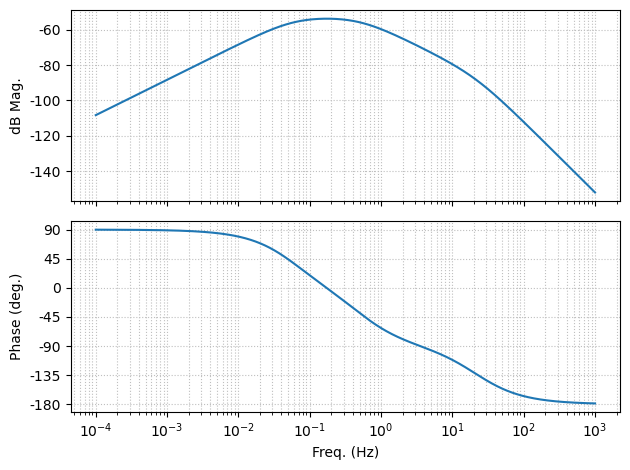

In [28]:
rbg.plot_bode_for_TF(G)
plt.tight_layout()

### Save $G$ if you need to email it to someone else or ask for help

In [29]:
rbg.preserve_G(G)

num = [1,0]
den = [  1.        ,140.25418788,491.28997707,163.01504112]
G = control.TransferFunction(num,den)


## Case 2: Bode System ID

- create a random TF without looking at it
- generate the Bode plot
- find the TF by "reading" the Bode plot
- check the answer when you are done

In [15]:
G2 = rbg.random_Bode_TF(max_poles=4)

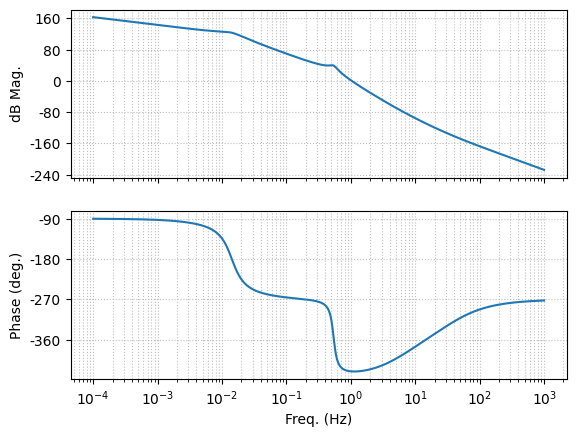

In [16]:
rbg.plot_bode_for_TF(G2)

### Check the answer

- the coefficients of the TF when multiplied out are not super important
- compare the poles and zeros you identified with the ones from the answer
    - keep in mind that the poles and zeros are in radians/second